# Workshop: a decision sandbox
> Four dilemma rounds on synthetic plumes, scored against plausible truths

This notebook builds the material for the workshop exercise in which participants choose a sampling plan and a restriction rule, and see what each choice costs. Each round is a small synthetic scene: a plume from a dispersion model, a few municipalities, 4 samples already taken and 10 left to place.

A single field would only show the luck of where samples fell. Each round is therefore scored against many plausible truths: fields drawn from the same model that agree with the 4 samples already taken. The scores answer the question participants face: given what is known, how often does each plan lead to a wrong decision? Everything runs in a minute or two. The scene maps can go on a form before the workshop, and the scores are shown afterwards.

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy.ndimage import gaussian_filter, rotate

## Synthetic plumes

A field is a Gaussian-plume trend times a lognormal residual, as in "A synthetic plume" in `_scoring_experiments.ipynb`, on a smaller grid of `W` by `W` cells. The permissible level is 1. The plant sits at `src` (row, column), just off the west edge, and the plume blows `angle` degrees counterclockwise from east. The residual's correlation is stretched along the plume. `angle_sd` makes the direction itself uncertain:

In [ ]:
W = 60

def trend(angle=0, spread=0.3, src=(30, -5), Q=14., bg=0.05):
    "Gaussian-plume concentration on the grid, relative to a permissible level of 1."
    r, c = np.mgrid[:W, :W].astype(float)
    r, c = r - src[0], c - src[1]
    t = np.deg2rad(angle)
    x, y = c * np.cos(t) - r * np.sin(t), c * np.sin(t) + r * np.cos(t)
    xp = np.maximum(x, 1.)
    return np.where(x > 0, Q / xp * np.exp(-y**2 / (2 * (spread * xp)**2)), 0) + bg

def residual(rng, angle=0, s_across=2, s_along=6):
    "Standardised Gaussian random field, correlated over `s_along` cells along `angle` and `s_across` across it."
    z = gaussian_filter(rng.standard_normal((2 * W, 2 * W)), (s_across, s_along), mode='wrap')
    z = rotate(z, angle, reshape=False, order=1)[W // 2:W // 2 + W, W // 2:W // 2 + W]
    return (z - z.mean()) / z.std()

def field(rng, angle=0, sd=0.8, angle_sd=0, **kw):
    "One plausible field: `trend` times a lognormal residual of `sd` log units, with the direction drawn around `angle`."
    a = angle + rng.normal(0, angle_sd) if angle_sd else angle
    return trend(a, **kw) * np.exp(sd * residual(rng, a))

The trend is the prior a dispersion model would give. One field drawn around it shows the patches the residual adds:

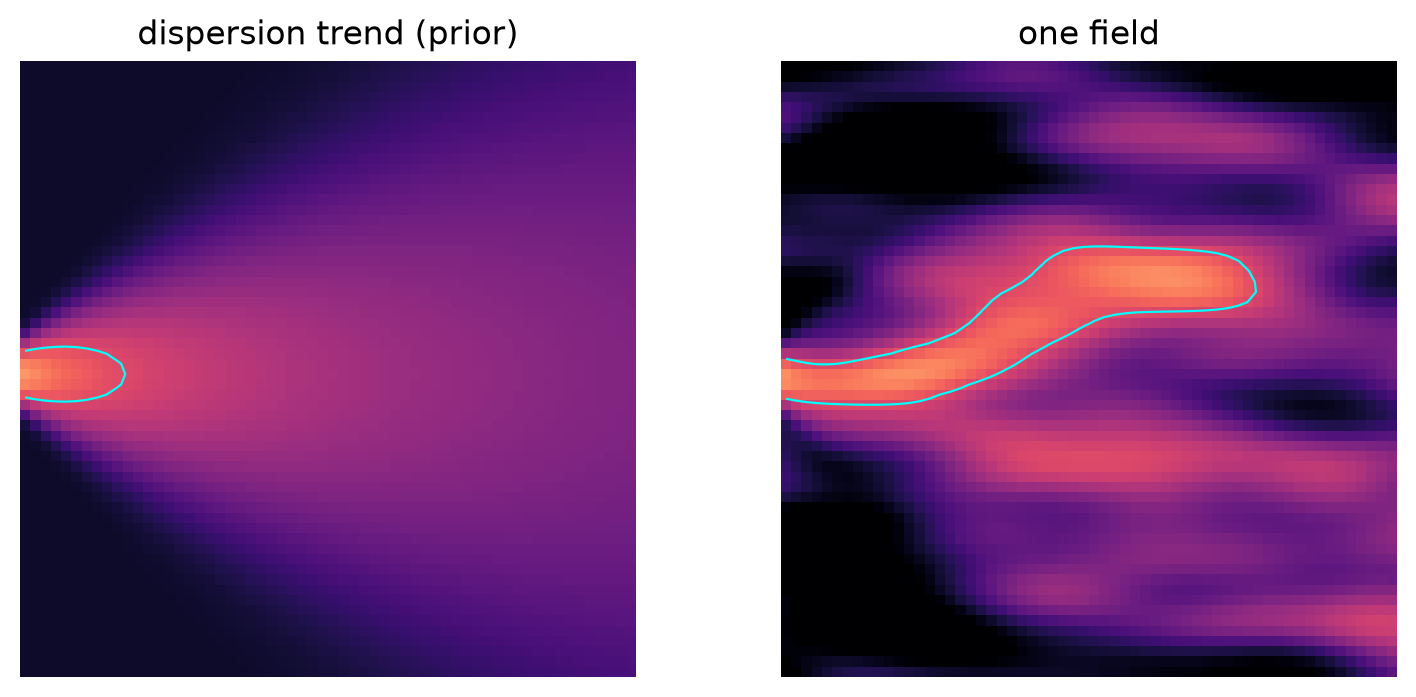

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(9, 4))
for ax, (title, f) in zip(axs, [('dispersion trend (prior)', trend()), ('one field', field(np.random.default_rng(1)))]):
    ax.imshow(np.log10(f), cmap='magma', vmin=-1.5, vmax=1)
    ax.contour(f, levels=[1], colors='cyan', linewidths=0.8)
    ax.set_title(title); ax.axis('off')

## Plausible truths

A scene holds the model's settings, the municipalities as rectangles `(row0, row1, col0, col1)`, and the samples already taken as `(row, col, above)`. `plausible` draws fields from the model and keeps those whose values at the initial samples are above or below the level as observed. This is conditional simulation by rejection. It conditions on the exceedances, not the values, which is what a card with red and open dots shows. A municipality truly needs a restriction when at least 10% of its cells are above the level, the dashboard's rule applied to the whole area:

In [ ]:
def above(f, rc): return f[rc[:, 0], rc[:, 1]] > 1

def plausible(scene, n=1000, seed=0, max_tries=500_000):
    "Fields drawn from the scene's model that agree with its initial samples, and the share of draws kept."
    rng, rc, obs = np.random.default_rng(seed), scene['init'][:, :2], scene['init'][:, 2].astype(bool)
    out, tries = [], 0
    while len(out) < n and tries < max_tries:
        f = field(rng, **scene['model'])
        tries += 1
        if (above(f, rc) == obs).all(): out.append(f)
    return np.array(out), len(out) / tries

def needs(f, box, accepted=0.1):
    "Whether the municipality `box` of field `f` truly needs a restriction."
    r0, r1, c0, c1 = box
    return (f[r0:r1, c0:c1] > 1).mean() >= accepted

## Rules and plans

A rule turns a municipality's samples (above the level or not) into a decision. `share_rule` is the DSS4NAFA dashboard's: restrict when at least 10% of the samples are above the level. `any_rule` restricts on a single exceedance, close to how restrictions were set in Japan after 2011 (see "How decisions are made in practice" in `scoring-design.md`). A municipality with no samples is not restricted:

In [ ]:
def share_rule(x, accepted=0.1): return len(x) > 0 and x.mean() >= accepted
def any_rule(x): return bool(x.any())
rules = {'share at least 10%': share_rule, 'any exceedance': any_rule}

A plan places the 10 new samples. `split` puts a number of uniform random samples in each municipality; `in_box` places them anywhere in a rectangle, and `line` along a transect, as from a road:

In [ ]:
def in_box(rng, box, k):
    "`k` uniform random cells in the rectangle `box`."
    r0, r1, c0, c1 = box
    return np.c_[rng.integers(r0, r1, k), rng.integers(c0, c1, k)]

def split(counts):
    "A plan placing `counts[name]` uniform random samples in each municipality."
    return lambda rng, munis: np.vstack([in_box(rng, munis[m], k) for m, k in counts.items() if k] or [np.empty((0, 2), int)])

def line(p0, p1, k, jitter=1.5):
    "A plan placing `k` samples evenly from cell `p0` to `p1`, each moved by up to `jitter` cells."
    def plan(rng, munis):
        t = (np.arange(k) + 0.5) / k
        rc = np.array(p0) + t[:, None] * (np.array(p1) - np.array(p0)) + rng.uniform(-jitter, jitter, (k, 2))
        return np.clip(np.rint(rc), 0, W - 1).astype(int)
    return plan

def lines(*plans): return lambda rng, munis: np.vstack([p(rng, munis) for p in plans])

`score` plays each plan once on every plausible field, applies each rule, and counts missed and unnecessary restrictions per campaign:

In [ ]:
def inside(rc, box):
    r0, r1, c0, c1 = box
    return (rc[:, 0] >= r0) & (rc[:, 0] < r1) & (rc[:, 1] >= c0) & (rc[:, 1] < c1)

def run(f, scene, plan, rng):
    "One campaign on field `f`: all samples as (row, col, above) after the plan."
    rc = np.vstack([scene['init'][:, :2], plan(rng, scene['munis'])])
    return np.c_[rc, above(f, rc)]

def decide(s, munis, rule): return {m: rule(s[inside(s[:, :2], b), 2].astype(bool)) for m, b in munis.items()}

def score(scene, plans, fs, seed=1):
    "Mean missed and unnecessary restrictions per campaign, for each rule and plan, over the plausible fields `fs`."
    rng, rows = np.random.default_rng(seed), []
    for f in fs:
        truth = {m: needs(f, b) for m, b in scene['munis'].items()}
        for p, plan in plans.items():
            s = run(f, scene, plan, rng)
            for r, rule in rules.items():
                d = decide(s, scene['munis'], rule)
                rows.append(dict(rule=r, plan=p, missed=sum(truth[m] and not d[m] for m in d), unnecessary=sum(d[m] and not truth[m] for m in d)))
    return pd.DataFrame(rows).groupby(['rule', 'plan'], sort=False).mean().loc[list(rules)].assign(wrong=lambda d: d.missed + d.unnecessary).round(2)

## Showing a round

`show_scene` draws what participants see: the prior, the municipality borders and the samples already taken, red when above the level and open when below. `show_example` draws one plausible truth, with the municipalities that need a restriction hatched, and one run of each plan, labelling each municipality's decision under the dashboard's rule:

In [ ]:
def draw_base(ax, scene, f, title):
    ax.imshow(np.log10(f), cmap='magma', vmin=-1.5, vmax=1)
    for m, (r0, r1, c0, c1) in scene['munis'].items():
        ax.add_patch(Rectangle((c0 - 0.5, r0 - 0.5), c1 - c0, r1 - r0, fill=False, ls='--', ec='white', lw=1))
        ax.text(c0 + 1, r0 + 3, m, color='white', fontsize=11, weight='bold')
    ax.set_title(title, fontsize=10); ax.axis('off')

def draw_samples(ax, s):
    up = s[:, 2].astype(bool)
    ax.scatter(s[up, 1], s[up, 0], c='red', s=25, ec='white', lw=0.5)
    ax.scatter(s[~up, 1], s[~up, 0], facecolors='none', ec='cyan', s=25)

def show_scene(scene, title='scene'):
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    draw_base(ax, scene, trend(**{k: v for k, v in scene['model'].items() if k not in ('sd', 'angle_sd')}), title)
    draw_samples(ax, scene['init'])

def show_example(scene, plans, f, seed=2):
    rng = np.random.default_rng(seed)
    fig, axs = plt.subplots(1, len(plans) + 1, figsize=(4 * (len(plans) + 1), 4))
    draw_base(axs[0], scene, f, 'one plausible truth')
    for m, b in scene['munis'].items():
        if needs(f, b): axs[0].add_patch(Rectangle((b[2] - 0.5, b[0] - 0.5), b[3] - b[2], b[1] - b[0], fill=False, hatch='//', ec='white', lw=0))
    for ax, (p, plan) in zip(axs[1:], plans.items()):
        s = run(f, scene, plan, rng)
        draw_base(ax, scene, f, p); draw_samples(ax, s)
        for m, d in decide(s, scene['munis'], share_rule).items():
            wrong = '' if d == needs(f, scene['munis'][m]) else (' (unneeded)' if d else ' (missed)')
            b = scene['munis'][m]
            ax.text(b[2] + 1, b[1] - 2, ('restrict' if d else 'no') + wrong, color='yellow' if wrong else 'white', fontsize=8)

## Round 1: the plume edge

Three municipalities along the plume, where it fades below the level. The prior says 1 is above the level, 3 probably below, and 2 is uncertain. Two samples in 1 are high, two in 3 are low. Plan A treats the municipalities alike (3, 4 and 3 samples), plan B places 10 random samples over the whole area, and plan C puts 8 in municipality 2 and 2 in municipality 3:

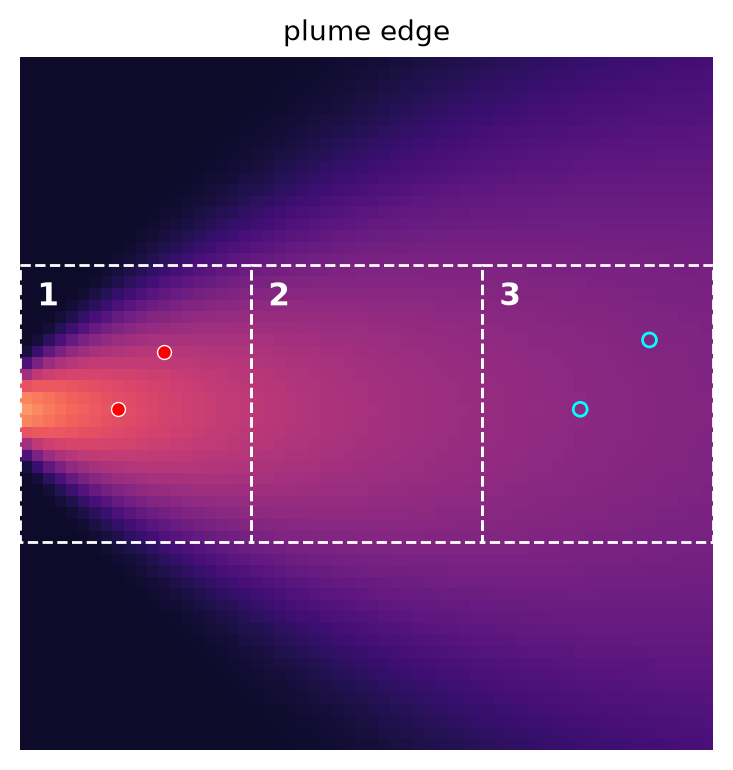

In [ ]:
edge = dict(model=dict(Q=14), munis={'1': (18, 42, 0, 20), '2': (18, 42, 20, 40), '3': (18, 42, 40, 60)},
            init=np.array([(30, 8, 1), (25, 12, 1), (30, 48, 0), (24, 54, 0)]))
edge_plans = {'A equal': split({'1': 3, '2': 4, '3': 3}), 'B random': lambda rng, munis: in_box(rng, (18, 42, 0, 60), 10),
              'C uncertain': split({'2': 8, '3': 2})}
show_scene(edge, 'plume edge')

About 1 field in 7 agrees with the four samples. Among those, municipality 1 always needs a restriction, 2 about half the time and 3 in about 1 case in 7:

In [ ]:
edge_fs, kept = plausible(edge)
kept, {m: np.mean([needs(f, b) for f in edge_fs]) for m, b in edge['munis'].items()}

(0.13751375137513752,
 {'1': np.float64(1.0), '2': np.float64(0.527), '3': np.float64(0.145)})

In [ ]:
edge_scores = score(edge, edge_plans, edge_fs)
assert edge_scores.loc[('share at least 10%', 'C uncertain'), 'wrong'] < edge_scores.loc[('share at least 10%', 'A equal'), 'wrong']
edge_scores

missed  unnecessary  wrong
rule               plan                                   
share at least 10% A equal        0.34         0.13   0.47
                   B random       0.37         0.13   0.50
                   C uncertain    0.21         0.17   0.38
any exceedance     A equal        0.34         0.13   0.47
                   B random       0.37         0.13   0.50
                   C uncertain    0.21         0.17   0.38

Plan C makes the fewest wrong decisions: it misses the restriction of municipality 2 least often, for slightly more unnecessary ones. All three plans cost the same 10 samples; only the placement differs. The two rules give the same decisions, because no municipality gets 11 samples or more: with 10 samples or fewer, one exceedance is already 10%. One example run:

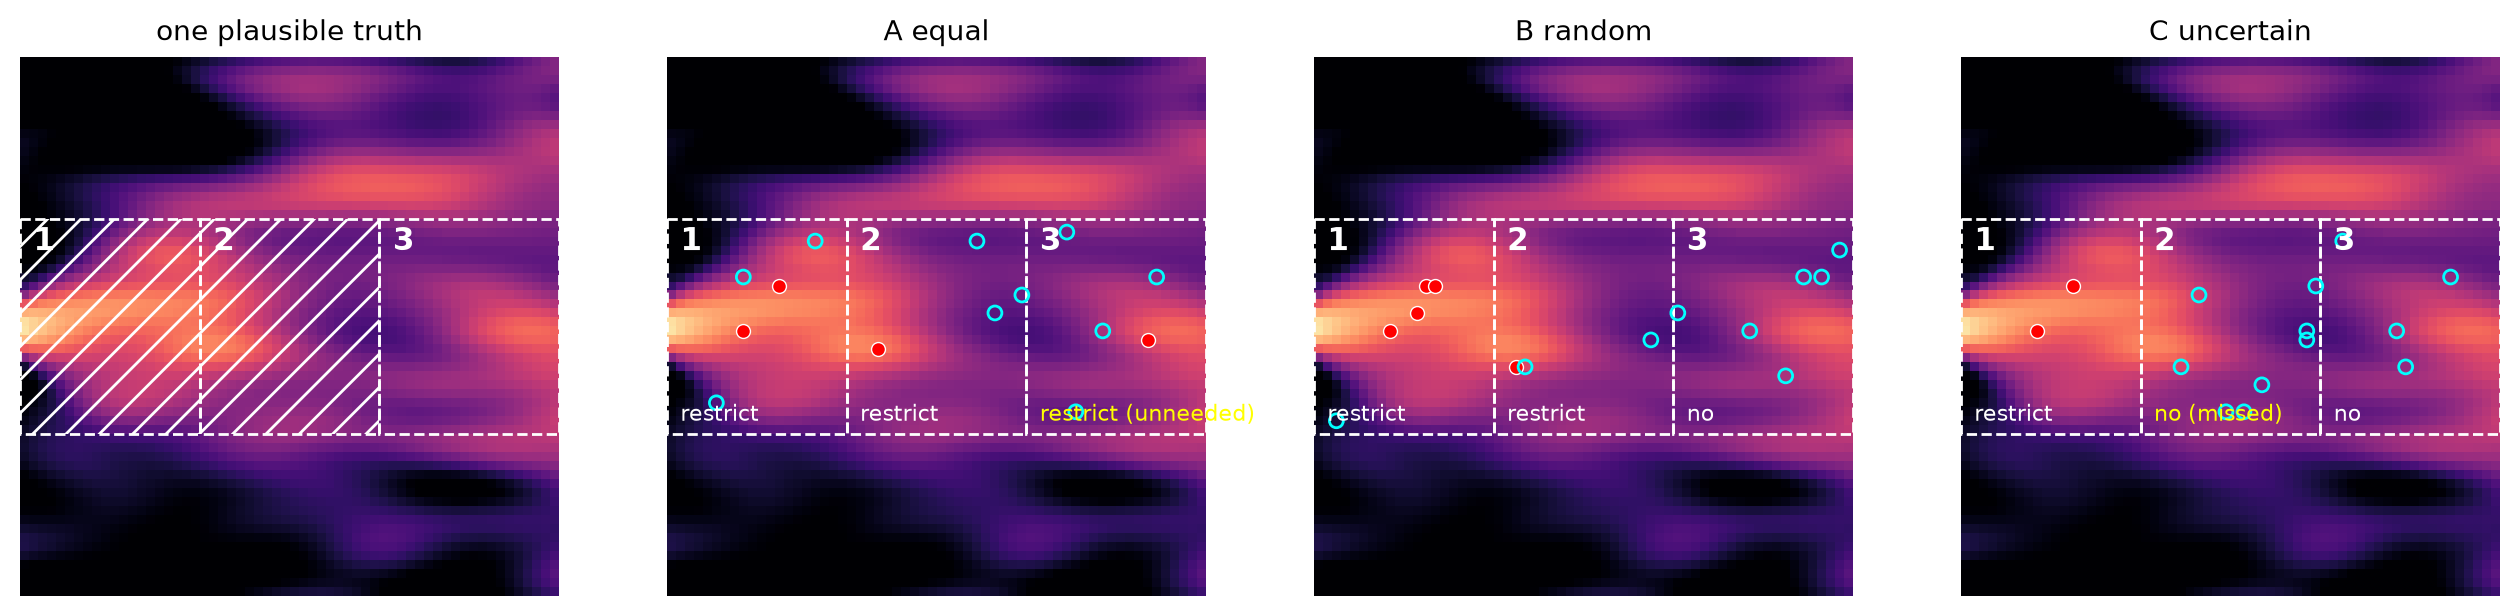

In [ ]:
show_example(edge, edge_plans, edge_fs[0])

## Round 2: near the plant

One municipality next to the plant, which the prior puts almost entirely above the level. Four samples, all high. Plan A spends all 10 remaining samples there, plan B spends 2, plan C none and keeps them for the rest of the region:

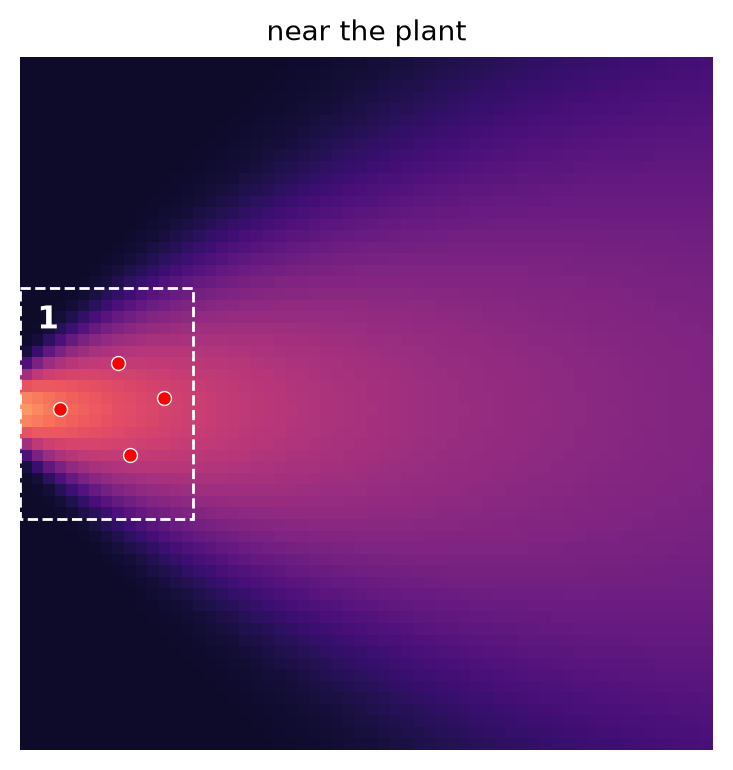

In [ ]:
near = dict(model=dict(Q=14), munis={'1': (20, 40, 0, 15)}, init=np.array([(30, 3, 1), (26, 8, 1), (34, 9, 1), (29, 12, 1)]))
near_plans = {'A all 10': split({'1': 10}), 'B 2 here': split({'1': 2}), 'C none': split({})}
show_scene(near, 'near the plant')

In [ ]:
near_fs, kept = plausible(near)
near_scores = score(near, near_plans, near_fs)
assert (near_scores.wrong == 0).all()
near_scores

missed  unnecessary  wrong
rule               plan                                
share at least 10% A all 10     0.0          0.0    0.0
                   B 2 here     0.0          0.0    0.0
                   C none       0.0          0.0    0.0
any exceedance     A all 10     0.0          0.0    0.0
                   B 2 here     0.0          0.0    0.0
                   C none       0.0          0.0    0.0

The municipality needs a restriction in every plausible truth, and every plan restricts it. More samples here cannot change the decision, so they have no value for it, although they may still serve as evidence for the people affected. Plan C keeps 10 samples, plan B 8 and plan A none.

## Round 3: the directional prior

The prior says the plume blows to the north-east (30°), but the true direction is uncertain by about 15°. Four municipalities: 1 north-west, 2 north-east, 3 around the plant, 4 south-east. Four samples near the plant are high. Plan A samples along the only road, which runs east along the south. Plan B samples along the prior's axis. Plan C crosses the plume twice, on two north-south transects:

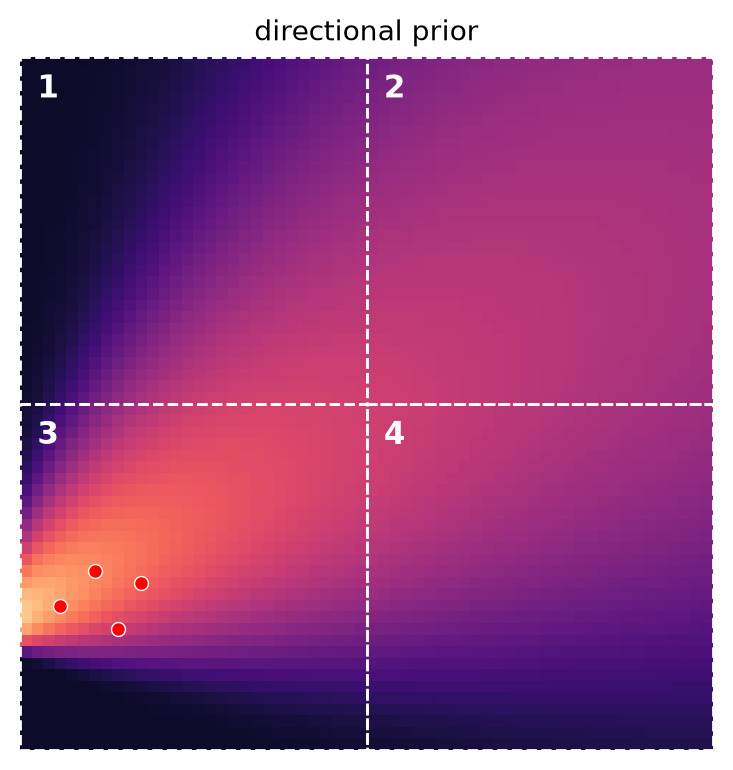

In [ ]:
directional = dict(model=dict(Q=30, angle=30, angle_sd=15, src=(50, -5)),
                   munis={'1': (0, 30, 0, 30), '2': (0, 30, 30, 60), '3': (30, 60, 0, 30), '4': (30, 60, 30, 60)},
                   init=np.array([(47, 3, 1), (44, 6, 1), (49, 8, 1), (45, 10, 1)]))
directional_plans = {'A road': line((53, 12), (53, 58), 10), 'B prior axis': line((40, 13), (10, 58), 10),
                     'C two crossings': lines(line((15, 15), (55, 25), 5), line((5, 40), (55, 50), 5))}
show_scene(directional, 'directional prior')

In [ ]:
directional_fs, kept = plausible(directional)
kept, {m: np.mean([needs(f, b) for f in directional_fs]) for m, b in directional['munis'].items()}

(0.2760143527463428,
 {'1': np.float64(0.095),
  '2': np.float64(0.524),
  '3': np.float64(1.0),
  '4': np.float64(0.658)})

In [ ]:
directional_scores = score(directional, directional_plans, directional_fs)
assert directional_scores.loc[('share at least 10%', 'C two crossings'), 'wrong'] < directional_scores.loc[('share at least 10%', 'A road'), 'wrong']
directional_scores

missed  unnecessary  wrong
rule               plan                                       
share at least 10% A road             1.09         0.02   1.10
                   B prior axis       0.89         0.23   1.13
                   C two crossings    0.65         0.18   0.83
any exceedance     A road             1.09         0.02   1.10
                   B prior axis       0.89         0.23   1.13
                   C two crossings    0.65         0.18   0.83

Plan A misses most: the road never enters municipality 2. Plan B trusts the prior and misses municipality 4 when the plume turns south. Plan C finds both edges and makes the fewest wrong decisions. Convenience has a cost in missed restrictions, which this round makes visible. One example run:

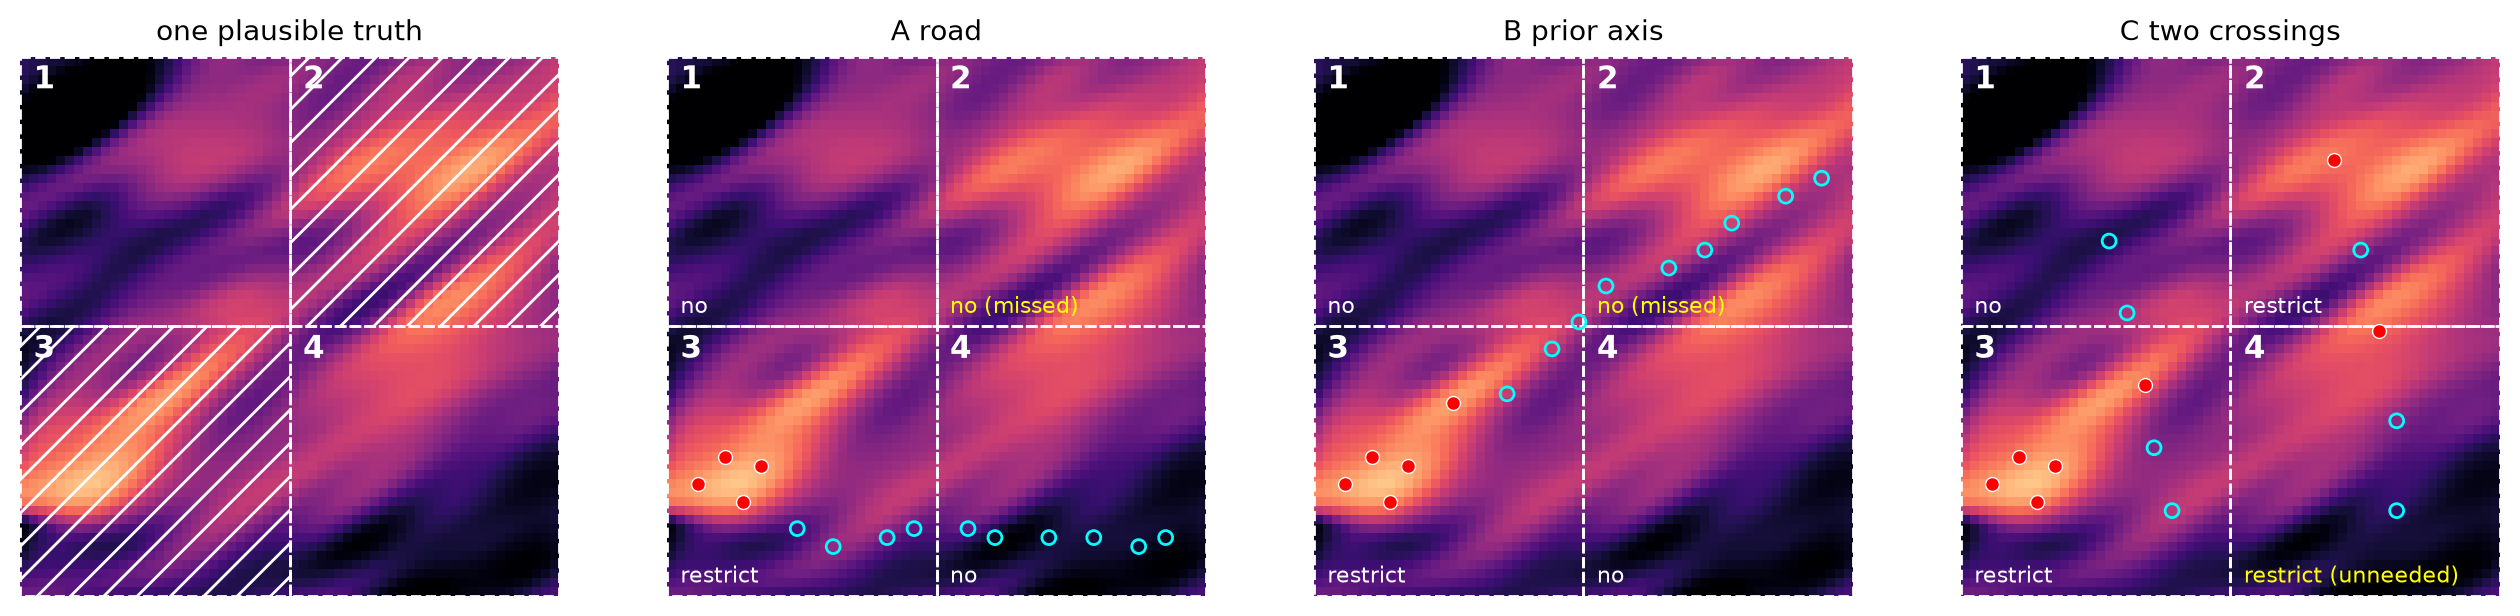

In [ ]:
show_example(directional, directional_plans, directional_fs[0])

## Round 4: the tight budget

Two municipalities share one team and 10 samples. In 1, on the plume's axis, the prior and both samples are high. In 2, north of the plume, the prior is mostly low, one sample near the plume is high and one is low. Plan A splits 5 and 5, plan B 3 and 7, plan C 0 and 10:

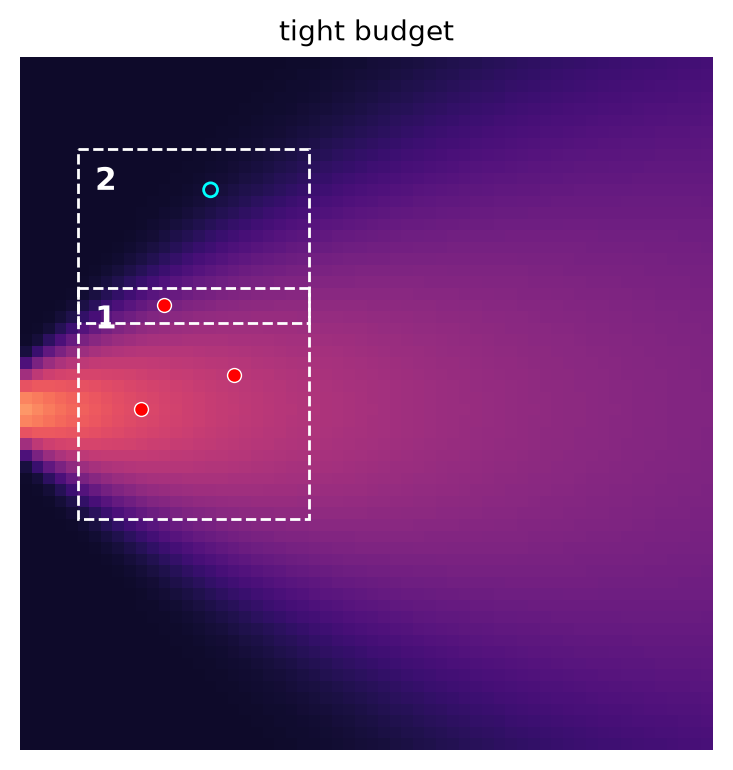

In [ ]:
budget = dict(model=dict(Q=14), munis={'1': (20, 40, 5, 25), '2': (8, 23, 5, 25)},
              init=np.array([(30, 10, 1), (27, 18, 1), (21, 12, 1), (11, 16, 0)]))
budget_plans = {'A 5 and 5': split({'1': 5, '2': 5}), 'B 3 and 7': split({'1': 3, '2': 7}), 'C 0 and 10': split({'2': 10})}
show_scene(budget, 'tight budget')

Only about 1 field in 200 agrees with these four samples, so this round takes about half a minute. Municipality 2 needs a restriction a little under half the time:

In [ ]:
budget_fs, kept = plausible(budget)
kept, {m: np.mean([needs(f, b) for f in budget_fs]) for m, b in budget['munis'].items()}

(0.00509871104584761, {'1': np.float64(1.0), '2': np.float64(0.442)})

In [ ]:
budget_scores = score(budget, budget_plans, budget_fs)
assert budget_scores.loc[('share at least 10%', 'C 0 and 10'), 'wrong'] < budget_scores.loc[('share at least 10%', 'A 5 and 5'), 'wrong']
budget_scores

missed  unnecessary  wrong
rule               plan                                  
share at least 10% A 5 and 5     0.00         0.56   0.56
                   B 3 and 7     0.00         0.55   0.55
                   C 0 and 10    0.08         0.28   0.36
any exceedance     A 5 and 5     0.00         0.56   0.56
                   B 3 and 7     0.00         0.56   0.56
                   C 0 and 10    0.00         0.56   0.56

Municipality 2 starts restricted: 1 of its 2 samples is above the level. Under the dashboard's rule, plans A and B keep it restricted (1 of 7 and 1 of 9), so it is restricted needlessly whenever it is in fact clean. Only plan C can bring its share below 10% (1 of 12) and lift the restriction, at the cost of a few missed ones. Under the any-exceedance rule, no plan can lift it: one high sample restricts for good. Here the rules differ, and the choice of rule matters as much as the split. One example run:

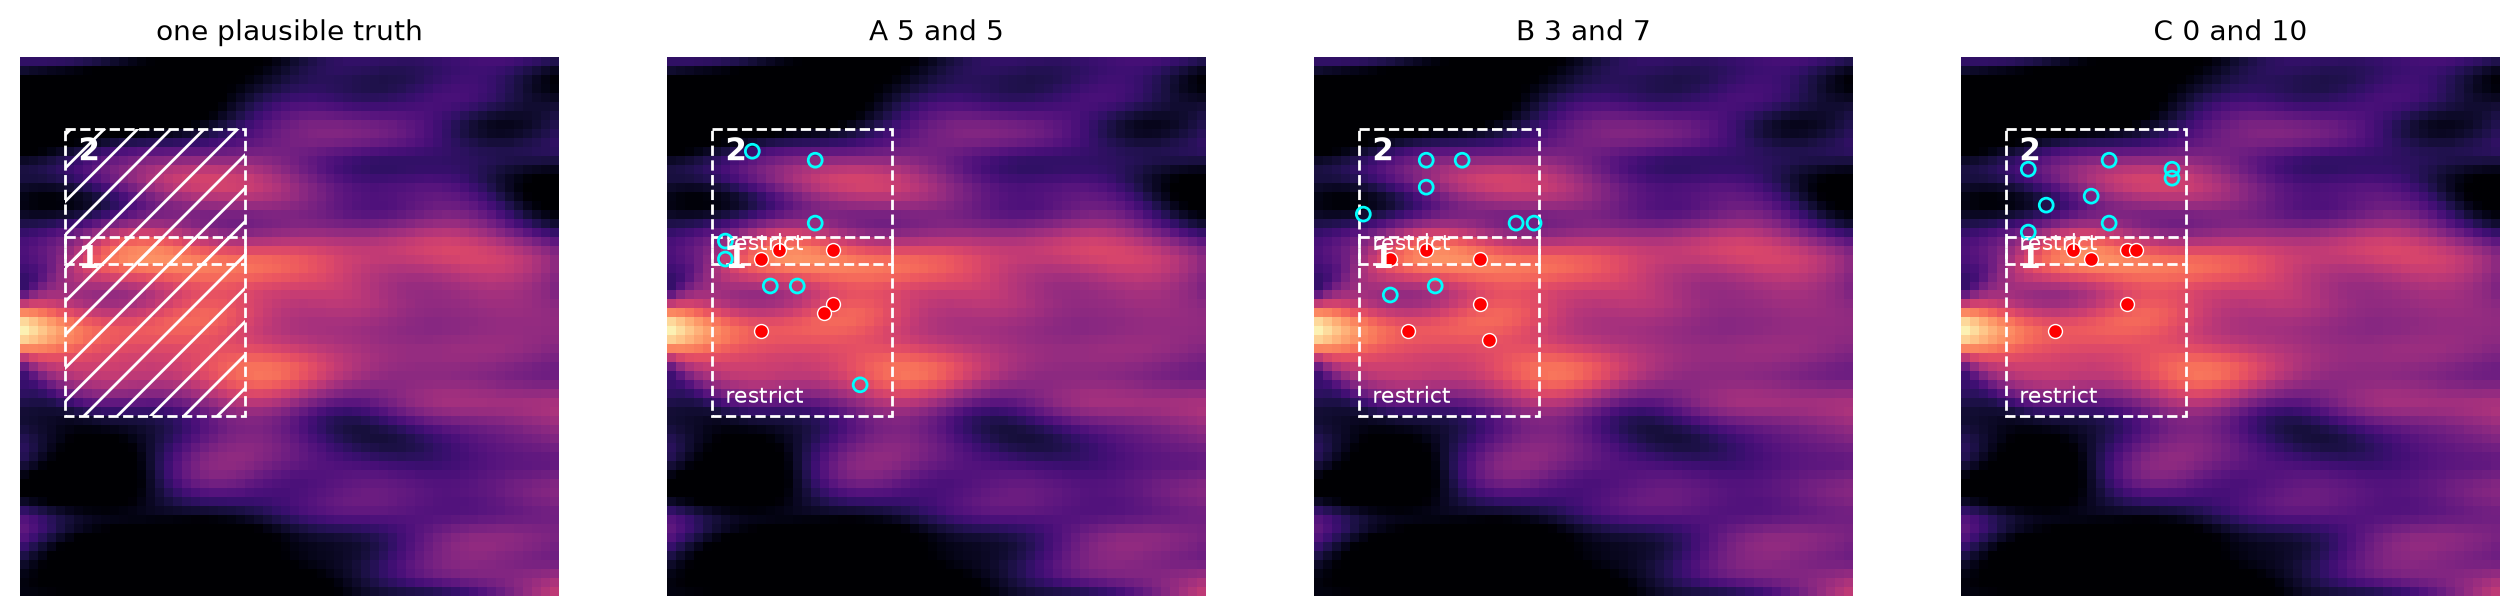

In [ ]:
show_example(budget, budget_plans, budget_fs[0])

## What the rounds show

- With the same 10 samples, placement changes how often a restriction is wrong: by about a fifth at the plume edge and by a quarter with the directional prior.
- Near the plant, samples cannot change the decision. Their value there is as evidence, which trufl does not score.
- With 10 samples or fewer in a municipality, the dashboard's 10% rule restricts on a single exceedance, like the any-exceedance rule. The rules differ only from 11 samples, which only plan C of the tight budget reaches.
- A rule that restricts on any exceedance can never lift a restriction with more samples. Lifting needs its own rule, as in Japan's 3 clean locations per municipality.

The scenes are synthetic and small, so the numbers illustrate the dilemmas rather than measure them.